---
title: "Steam methane reforming: the Xu-Froment intrinsic kinetics"
description: "The most-used rate equations in reformer modelling, rebuilt from the 1989 tables and put back against the runs plotted in the paper's own Figures 2 and 3."
categories: [sec:C, struct:S1, struct:S2, tier:T1, data:tier2, data:tier4, phase:gas, phase:gas-solid]
date: 2026-07-26
---

# Steam methane reforming: the Xu-Froment intrinsic kinetics

**Catalog ID:** `C2.1` · **Structures:** `S1` (0D/1D reaction network), `S2` (plug flow with reaction) · **Tier:** T1

Almost every steam-reformer simulation published since 1989 uses the same three
rate equations. They come from one paper, and getting them wrong is easy: the
scan mangles the exponents, the reference temperature is not the same for all
seven parameters, and two different activity factors float around the text.
This page rebuilds them from the tables and puts them back against the
measurements they were fitted to.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.04.3"  # replaced by the release tag at publication
PYMRM = ">=3.3.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "C2.1-xu-froment-smr"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. The page's model.py is put on sys.path by setup().
import re
from dataclasses import replace

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.optimize import brentq
from pymrm.checks import observed_orders
from gallery_utils import Claims, cite_data, load_data, load_meta
from model import (ATOMS, R_KJ, SPECIES, STOICH, SteamReformer, XuFroment, half_ulp,
                   partial_pressures, reference_profile, reference_solution, round_trip)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
EPS = np.finfo(float).eps
BREAK = []   # (injected defect, claim, clean value, broken value, caught)


def brk(row, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(row, metric, broken)
    BREAK.append((row, metric, claims[metric], broken, caught))

## Background

Steam reforming is how most of the world's hydrogen is made. Methane and steam
go into rows of tubes packed with a nickel catalyst, sitting in a fired furnace
at 675-1000 K and 30 bar, and come out as synthesis gas. The tubes are the most
expensive part of the plant and they fail by creep, so how fast the reaction
actually runs, and therefore how much heat has to cross the tube wall and
where, is a materials question as much as a chemical one.

Before 1989 most published kinetics were *effective* rate equations: fitted on
industrial-size pellets, with the (severe) internal diffusion limitation
absorbed into the constants. Those cannot be transferred to a different pellet,
and they cannot be combined with a diffusion model without double-counting.

Xu and Froment set out to measure the **intrinsic** kinetics instead, on
catalyst crushed to 0.18-0.25 mm, where they show diffusion no longer limits,
and to do it mechanistically rather than by curve-fitting a power law. They
enumerated 11 candidate reactions, cut them down thermodynamically, built two
surface mechanisms, generated 21 candidate sets of three rate equations from
them, and discriminated between the sets on 220 steam-reforming runs plus 60
runs on the reverse water-gas shift and methanation.

What survived is the triangular scheme

$$
\mathrm{I}\;\;\mathrm{CH_4 + H_2O \rightleftharpoons CO + 3H_2}, \qquad
\mathrm{II}\;\;\mathrm{CO + H_2O \rightleftharpoons CO_2 + H_2}, \qquad
\mathrm{III}\;\;\mathrm{CH_4 + 2H_2O \rightleftharpoons CO_2 + 4H_2},
$$

with reaction III a *parallel* route to CO₂ rather than CO₂ being formed only
through CO. That was the paper's substantive claim, and it came from the data:
the ratio $V(\mathrm{II})$ does not extrapolate to the origin as space time
goes to zero, so some CO₂ must be produced directly from methane.

## The published model

**Rate equations** (the paper's Eqs. 3). All three share one denominator,
because all three are assumed to occur on the same active sites:

$$
r_1 = \frac{k_1}{p_{\mathrm{H_2}}^{2.5}}
      \left( p_{\mathrm{CH_4}} p_{\mathrm{H_2O}}
             - \frac{p_{\mathrm{H_2}}^{3} p_{\mathrm{CO}}}{K_1} \right) \Big/ \mathrm{DEN}^2
$$

$$
r_2 = \frac{k_2}{p_{\mathrm{H_2}}}
      \left( p_{\mathrm{CO}} p_{\mathrm{H_2O}}
             - \frac{p_{\mathrm{H_2}} p_{\mathrm{CO_2}}}{K_2} \right) \Big/ \mathrm{DEN}^2
$$

$$
r_3 = \frac{k_3}{p_{\mathrm{H_2}}^{3.5}}
      \left( p_{\mathrm{CH_4}} p_{\mathrm{H_2O}}^{2}
             - \frac{p_{\mathrm{H_2}}^{4} p_{\mathrm{CO_2}}}{K_3} \right) \Big/ \mathrm{DEN}^2
$$

$$
\mathrm{DEN} = 1 + K_{\mathrm{CO}} p_{\mathrm{CO}} + K_{\mathrm{H_2}} p_{\mathrm{H_2}}
             + K_{\mathrm{CH_4}} p_{\mathrm{CH_4}}
             + K_{\mathrm{H_2O}} \frac{p_{\mathrm{H_2O}}}{p_{\mathrm{H_2}}}
$$

There is **no $K_{\mathrm{CO_2}}$ term.** It was never statistically
significant, from either data set, and the paper says so explicitly. Adding one
is a common way to silently change the model.

**Species rates** (Eq. 4), for steam reforming:

$$
r_{\mathrm{CO}} = r_1 - r_2, \qquad
r_{\mathrm{CO_2}} = r_2 + r_3, \qquad
r_{\mathrm{CH_4}} = r_1 + r_3
$$

**Reactor** (Eq. 1). The kinetic runs were done in an integral fixed bed,
isothermal and isobaric, integrated in the space time $W/F^{0}_{\mathrm{CH_4}}$:

$$
\frac{\mathrm{d}x_{\mathrm{CH_4}}}{\mathrm{d}(W/F^{0}_{\mathrm{CH_4}})} = r_{\mathrm{CH_4}},
\qquad
\frac{\mathrm{d}x_{\mathrm{CO_2}}}{\mathrm{d}(W/F^{0}_{\mathrm{CH_4}})} = r_{\mathrm{CO_2}},
\qquad x = 0 \;\text{at}\; W/F^{0}_{\mathrm{CH_4}} = 0 .
$$

Two of the three species rates are independent, so two conversions describe the
whole composition: $x_{\mathrm{CH_4}}$, the total methane converted, and
$x_{\mathrm{CO_2}}$, the part of it that ended up as CO₂. Per mol of methane
fed, CH₄ is $1-x_{\mathrm{CH_4}}$, H₂O is $s - x_{\mathrm{CH_4}} - x_{\mathrm{CO_2}}$,
H₂ is $h + 3x_{\mathrm{CH_4}} + x_{\mathrm{CO_2}}$, CO is
$x_{\mathrm{CH_4}} - x_{\mathrm{CO_2}}$ and CO₂ is $x_{\mathrm{CO_2}}$, with $s$
and $h$ the feed ratios H₂O/CH₄ and H₂/CH₄.

| symbol | name in the code |
|---|---|
| $x_{\mathrm{CH_4}}, x_{\mathrm{CO_2}}$ | `u[:, 0]`, `u[:, 1]` of `SteamReformer` |
| $W/F^{0}_{\mathrm{CH_4}}$ | `tau` |
| $k_i, K_j$ | `XuFroment.constants(T)` |
| $K_1, K_2, K_3$ | `XuFroment.equilibrium(T)` |
| $r_1, r_2, r_3$ | `XuFroment.rates(...)` |
| $s, h, p_t$ | `sr`, `hr`, `p_t` |

## Parameters and assumptions

**Assumptions:** isothermal and isobaric plug flow; intrinsic kinetics (the
paper demonstrates no internal limitation at 0.18-0.25 mm and calculates
external transport to be negligible); ideal gas; no carbon deposition, which
the thermodynamic analysis rules out at these conditions; and the catalyst held
at a fixed activity level, which is how the authors corrected their space times.

**Three traps in this paper.** Each one silently changes the answer:

1. **The reference temperature is not the same for all parameters.**
   $T_r = 648$ K for $k_1, k_2, k_3, K_{\mathrm{CO}}$ and $K_{\mathrm{H_2}}$,
   but $T_r = 823$ K for $K_{\mathrm{CH_4}}$ and $K_{\mathrm{H_2O}}$. Using one
   reference for all seven biases the temperature dependence (Validation, check 1,
   prints by how much).
2. **Three activity levels.** Table 6 is footnoted *reference activity*, the
   partially deactivated catalyst. Multiply the rate coefficients by **1.225**
   for the reverse water-gas shift and methanation reference level (the curves
   in the paper's Figures 4 and 5 were drawn that way), and by **2.246** for
   fresh catalyst. The steam-reforming data used here need *neither*.
3. **The exponents do not survive OCR.** In the PDF text layer
   $8.664 \times 10^{-7}$ comes out as `8.664 lo-'`. Every parameter below was
   read from a 600 dpi render of the printed page instead, and none was
   repaired by inference: a misread exponent is a wrong rate constant with no
   outward sign. The Table 5 to Table 6 round trip in the validation section is
   the check on that reading.

**What the paper does not give: the equilibrium constants.** $K_1$, $K_2$ and
$K_3$ appear in the rate equations but are tabulated nowhere in it, so they must
come from elsewhere. This page uses the correlations usually quoted with these
kinetics (Twigg, *Catalyst Handbook*, 2nd ed., 1989),
$K_1 = \exp(-26830/T + 30.114)$ bar², $K_2 = \exp(4400/T - 4.036)$ and
$K_3 = K_1 K_2$, and then tests them against the paper's own Table 7 reaction
enthalpies, which is the strongest consistency check available without
importing a thermodynamic database.

In [3]:
par = load_data("xu-froment-1989-parameters.csv", page=PAGE)
par_txt = load_data("xu-froment-1989-parameters.csv", page=PAGE, dtype=str)  # as printed
obs = load_data("xu-froment-1989-conversion.csv", page=PAGE)
obs_meta = load_meta("xu-froment-1989-conversion.csv", page=PAGE)
cond = obs_meta["conditions"]

P_T = float(cond["pressure_bar"])     # total pressure, bar (figure captions)
SR = float(cond["h2o_ch4_molar"])     # H2O/CH4 in the feed (figure captions)
HR = float(cond["h2_ch4_molar"])      # H2/CH4 in the feed (Table 1)
TEMPS = [float(T) for T in cond["temperatures_K"]]   # K, the four curves
TAU_MAX = 0.45                        # g_cat h / mol_CH4, beyond the last run
N_TAU = 1000                          # cells in tau (Validation, check 4)
kin = XuFroment.from_table(par)       # Table 6 A, Table 5 E, the correlation above
print(f"p_t = {P_T} bar, H2O/CH4 = {SR}, H2/CH4 = {HR}, T = {TEMPS} K")

p_t = 10.0 bar, H2O/CH4 = 3.0, H2/CH4 = 1.25, T = [773.0, 798.0, 823.0, 848.0] K


## The data

Two datasets, both extracted from the paper and both carrying a provenance
sidecar.

The **parameters** are Tables 5 and 6 read off a 600 dpi page render. The
**measurements** are the experimental markers of Figures 2 and 3: total
methane conversion and conversion into CO₂ against space time, at the
conditions printed above, at four temperatures. The smooth curves on those
figures are the authors' own model and were deliberately *not* extracted, so
what follows compares this implementation against measurements rather than
against someone else's fit. The sidecar records the cross-figure pairing of
the two digitisations, the carbon closure $x_{\mathrm{CO_2}} \le x_{\mathrm{CH_4}}$
and one merged glyph in Figure 2 that was recorded once rather than guessed.

In [4]:
print(par[["symbol", "A", "E_or_dH_kJ_per_mol", "value_at_Tref", "T_ref_K"]]
      .to_string(index=False))
print()
print(obs.groupby(["quantity", "temperature_K"]).size().unstack().to_string())
N_OBS = len(obs)
print(f"\n{N_OBS} measurements ({(obs.quantity == 'x_CH4').sum()} x_CH4, "
      f"{(obs.quantity == 'x_CO2').sum()} x_CO2), W/F from {obs.W_F.min():.3f} to "
      f"{obs.W_F.max():.3f} g_cat h/mol_CH4")
claims.value("W_F_measured_max", obs.W_F.max(), unit="g_cat h/mol_CH4",
             note="the last measured space time; the computed bed ends at TAU_MAX")
_err = " ".join(obs_meta["acquisition"]["estimated_error"].split())
brk("the bed outlet TAU_MAX read as the last measurement", "W_F_measured_max", TAU_MAX)
print("digitisation error (sidecar): " + _err)
claims.value("digitisation_error_conversion",
             float(re.search(r"\+/-\s*([0-9.]+) in conversion", _err).group(1)),
             note="read from the data sidecar's estimated_error")
brk("regular expression matching the W/F error instead of the conversion error",
    "digitisation_error_conversion",
    float(re.search(r"\+/-\s*[0-9.]+ in conversion and \+/-\s*([0-9.]+) in W/F", _err).group(1)))
print(cite_data(obs_meta))

symbol            A  E_or_dH_kJ_per_mol  value_at_Tref  T_ref_K
    k1 4.225000e+15              240.10       0.000184      648
    k2 1.955000e+06               67.13       7.558000      648
    k3 1.020000e+15              243.90       0.000022      648
  K_CO 8.230000e-05              -70.65      40.910000      648
  K_H2 6.120000e-09              -82.90       0.029600      648
 K_CH4 6.650000e-04              -38.28       0.179100      823
 K_H2O 1.770000e+05               88.68       0.415200      823

temperature_K  773  798  823  848
quantity                         
x_CH4            6    5   13    6
x_CO2            6    5   14    6

61 measurements (30 x_CH4, 31 x_CO2), W/F from 0.128 to 0.405 g_cat h/mol_CH4
digitisation error (sidecar): +/- 0.0006 in conversion and +/- 0.0007 in W/F, dominated by placing the centre of a ~20 px glyph that overlaps a ~10 px curve, plus the tick residuals quoted above.
Xu, J.; Froment, G. F. (1989) — AIChE Journal 35(1) 88-96 — doi:10.1002/aic.

## PyMRM implementation

The reactor is pure convection with a source: $\mathrm{d}(v\,x)/\mathrm{d}\tau
= r$ with $v = 1$ and $\tau = W/F^{0}_{\mathrm{CH_4}}$. That is
`construct_convflux_upwind` followed by `construct_div` (`nu=0`), exactly as for
a plug flow in space: the coordinate being a space time rather than a length
changes nothing about the operators. Both are assembled once in
`SteamReformer._build_operators`.

**Boundary conditions**, on the outward normal. At the inlet ($-\tau$) the
conversions are zero, $x = 0$: `{"a": 0, "b": 1, "d": 0}`. The outlet is a
pure convective outflow, `{"outflow": True}`: what leaves is what the last cell
holds, and no condition is imposed on the profile. The outlet value is read on
the outlet face with `compute_boundary_values` (`SteamReformer.outlet`).

**State and Jacobian.** The state is `(n_tau, 2)`, space time first and the two
conversions last. The source at a cell depends only on that cell's two
conversions, so the default `NumJac(shape)` stencil, which couples the last axis
in full, has exactly the structure of the true Jacobian: one $2\times2$ block per
cell. Nothing here needs `axes_diagonals`; the coupling between cells comes in
analytically through the convection operator. `newton` starts from $x = 0$ and
`solve` raises unless it converges.

**What first-order upwind means here.** With $v = 1$ the upwind balance of cell
$i$ is $(u_i - u_{i-1})/\Delta\tau = r(u_i)$: backward Euler in $\tau$. Reading
a measurement at an arbitrary $\tau$ needs an interpolation, and two readings
are natural: between cell centres, or between the upwind face values (each cell
value placed at its downstream face). Both are first order; check 4 measures
which one is closer to the exact profile.

In [5]:
def solve_all(k, n_tau=N_TAU, **kw):
    """The four isothermal reactors of Figures 2 and 3 for kinetics ``k``."""
    return {T: SteamReformer(k, T, P_T, SR, HR, tau_max=TAU_MAX, n_tau=n_tau, **kw).solve()
            for T in TEMPS}


models = solve_all(kin)
for T, m in models.items():
    print(f"T = {T:.0f} K   Newton iterations: {m.result.nit}   "
          f"backward error (here {m.backward_error():.1e})")

T = 773 K   Newton iterations: 4   backward error (here 1.9e-16)
T = 798 K   Newton iterations: 4   backward error (here 3.1e-16)
T = 823 K   Newton iterations: 4   backward error (here 1.3e-15)
T = 848 K   Newton iterations: 5   backward error (here 2.2e-16)


## Results

The two panels are the paper's Figures 2 and 3 rebuilt: markers are the
digitised measurements, lines are this implementation. Nothing was fitted:
every parameter is Table 6 as printed.

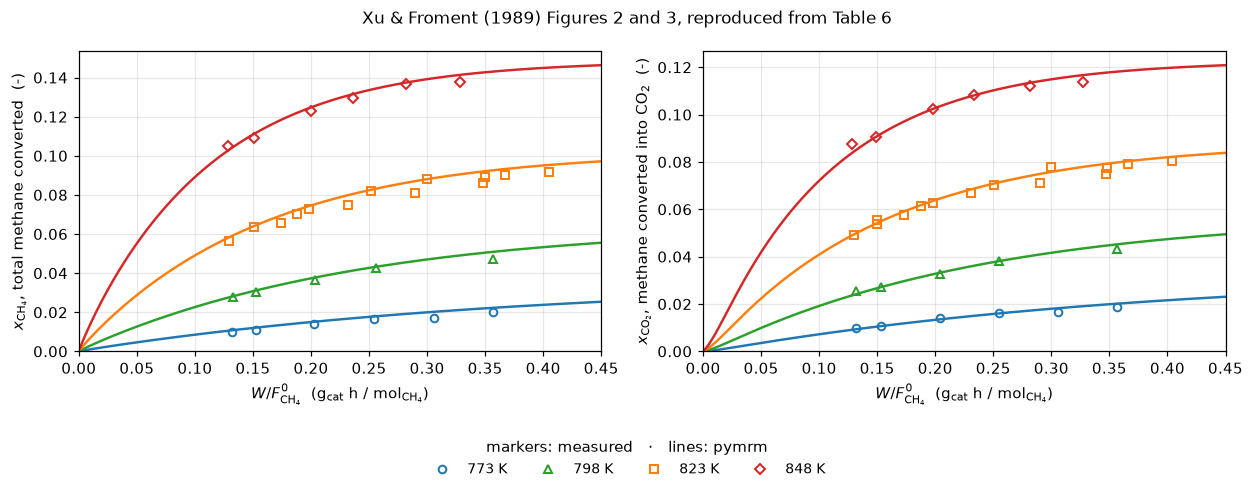

In [6]:
COL = {773.0: "tab:blue", 798.0: "tab:green", 823.0: "tab:orange", 848.0: "tab:red"}
MRK = {773.0: "o", 798.0: "^", 823.0: "s", 848.0: "D"}
FIELD = {"x_CH4": 0, "x_CO2": 1}

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), sharex=True)
for ax, (q, lab) in zip(axes, [("x_CH4", r"$x_{\mathrm{CH_4}}$, total methane converted"),
                               ("x_CO2", r"$x_{\mathrm{CO_2}}$, methane converted into CO$_2$")]):
    for T in TEMPS:
        m = models[T]
        ax.plot(m.tau_c, m.u[:, FIELD[q]], color=COL[T], lw=1.6)
        s = obs[(obs.quantity == q) & (obs.temperature_K == T)]
        ax.plot(s.W_F, s.value, MRK[T], color=COL[T], ms=5, mfc="none", mew=1.3,
                label=f"{T:.0f} K")
    ax.set_xlabel(r"$W/F^{0}_{\mathrm{CH_4}}$  (g$_\mathrm{cat}$ h / mol$_{\mathrm{CH_4}}$)")
    ax.set_ylabel(lab + "  (-)")
    ax.set_xlim(0, TAU_MAX)
    ax.set_ylim(0, None)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=9, frameon=False,
           title="markers: measured   ·   lines: pymrm")
fig.suptitle("Xu & Froment (1989) Figures 2 and 3, reproduced from Table 6", fontsize=11)
fig.tight_layout(rect=(0, 0.13, 1, 1))
plt.show()

In [7]:
def deviations(ms, read="centre"):
    """Model minus measurement at every digitised point, in the order of ``obs``."""
    return np.array([ms[r.temperature_K].at(r.W_F, FIELD[r.quantity], read=read) - r.value
                     for r in obs.itertuples()])


res = obs.copy()
res["dev"] = deviations(models)
res["model"] = res.value + res.dev
summary = (res.groupby(["quantity", "temperature_K"])["dev"]
             .agg(n="size", MAD=lambda s: s.abs().mean(),
                  worst=lambda s: s.abs().max(), bias="mean").round(5))
print(summary.to_string())
print(f"\noverall: n = {len(res)}   MAD = {res.dev.abs().mean():.5f}   "
      f"worst = {res.dev.abs().max():.5f}   bias = {res.dev.mean():+.5f}")

                         n      MAD    worst     bias
quantity temperature_K                               
x_CH4    773             6  0.00170  0.00322  0.00170
         798             5  0.00146  0.00387  0.00146
         823            13  0.00282  0.00582  0.00279
         848             6  0.00208  0.00368  0.00137
x_CO2    773             6  0.00073  0.00174  0.00030
         798             5  0.00081  0.00206  0.00019
         823            14  0.00153  0.00435  0.00104
         848             6  0.00137  0.00390 -0.00003

overall: n = 61   MAD = 0.00172   worst = 0.00582   bias = +0.00130


## Validation

Five checks. The first two test the *parameters*, the part of this page that a
bad page render would silently corrupt; the third tests the mole bookkeeping;
the fourth the discretisation and the solver against an independent
integration; the fifth the model against the measurements. Every number is
registered as a claim, and each check injects the defects it is meant to catch,
through an argument or a parameter, and prints whether the claim's own check
fails. The break table at the end of "What pymrm adds" collects every row.

**A blind spot in the obvious summary of check 1.** The worst per-row
round-trip deviation is a `max()` over seven rows, and its baseline scatter is
set by the *printed precision of the activation energies*: E is given to
0.1 kJ/mol, and at $T_r = 648$ K that alone is worth 0.93 % on `A`. So `k1` and
`k3` carry the largest deviations in the table with nothing wrong at all, and a single-digit slip
that lands below that ceiling leaves the worst deviation unchanged. A `max()` is
only as sharp as its own baseline scatter. The page therefore also normalises
each row by *its own* printed precision and sums the seven ratios, a statistic
that every row reaches.

In [8]:
# 1. Table 5 -> Table 6 round trip. A = value(T_ref) exp(E / (R T_ref)) for the rate
#    coefficients, and the same with dH for the adsorption constants. It tests both
#    readings at once, and the split reference temperature, which is in the formula.
#    The printed digits come from the CSV read as text, so the precision of every
#    entry is the precision it was printed with.
ROWS = [dict(symbol=r.symbol, A=r.A, E=r.E_or_dH_kJ_per_mol, val=r.value_at_Tref,
             T_ref=float(r.T_ref_K)) for r in par_txt.itertuples()]


def rt_metrics(rows, T_ref=None):
    rt = round_trip(rows, T_ref=T_ref)
    return (max(r["rel_pct"] for r in rt), max(r["ratio"] for r in rt),
            sum(r["ratio"] for r in rt), rt)


def rows_with(symbol, key, new):
    """The printed rows with one entry of ``symbol`` replaced by the string ``new``."""
    out = [dict(r) for r in ROWS]
    for r in out:
        if r["symbol"] == symbol:
            r[key] = new
    return out


RT_WORST_PCT, RT_WORST_RATIO, RT_RATIO_SUM, RT = rt_metrics(ROWS)
print("1. Table 5 -> Table 6 round trip, each row against its own printed precision")
print(f"   {'symbol':6s} {'T_ref':>6s} {'A':>10s} {'A computed':>11s} {'rel %':>8s} "
      f"{'bound %':>8s} {'ratio':>7s}")
for r in RT:
    print(f"   {r['symbol']:6s} {r['T_ref']:6.0f} {r['A']:10.4g} {r['A_computed']:11.4g} "
          f"{r['rel_pct']:8.4f} {r['bound_pct']:8.4f} {r['ratio']:7.3f}")
E_SHARE = half_ulp(ROWS[0]["E"]) / (R_KJ * ROWS[0]["T_ref"]) * 100
print(f"   worst deviation {RT_WORST_PCT:.4f} %; half a unit of E = {ROWS[0]['E']} kJ/mol "
      f"at {ROWS[0]['T_ref']:.0f} K is {E_SHARE:.2f} % on A by itself")
print(f"   worst ratio to printed precision {RT_WORST_RATIO:.2f}, sum over the seven rows "
      f"{RT_RATIO_SUM:.3f}")

# The same round trip with 648 K forced on every parameter: the split reference
# temperature is not a detail one can round off.
TREF = {r["symbol"]: r["A_computed"] / r["A"] for r in round_trip(ROWS, T_ref=648.0)}
print("   with 648 K for every parameter:   "
      + "   ".join(f"{s} off by a factor of {TREF[s]:.3g}" for s in ("K_CH4", "K_H2O")))

claims.value("param_round_trip_worst_pct", RT_WORST_PCT, unit="%")
claims.value("param_round_trip_worst_ratio_to_precision", RT_WORST_RATIO)
claims.value("param_round_trip_ratio_sum", RT_RATIO_SUM)
claims.value("e_precision_share_pct", E_SHARE, unit="%",
             note="half a unit of k1's printed E at 648 K, as a share of A")
claims.value("tref_slip_factor_K_CH4", TREF["K_CH4"])
claims.value("tref_slip_factor_K_H2O", TREF["K_H2O"])

print("\n   injected transcription defects (each re-runs the round trip):")
print(f"   {'injected defect':46s}{'worst %':>10}{'worst ratio':>13}{'sum ratios':>12}")
print(f"   {'as printed':46s}{RT_WORST_PCT:10.4f}{RT_WORST_RATIO:13.2f}{RT_RATIO_SUM:12.3f}")
RT_DEFECTS = [("K_CO", "A", "8.32e-5"), ("k3", "A", "1.002e15"), ("K_H2O", "A", "1.71e5"),
              ("k2", "A", "1.965e6"), ("k1", "A", "4.226e15"), ("k1", "E", "240.2"),
              ("K_CH4", "val", "0.1719"), ("k1", "E", "241.1"), ("k1", "A", "4.225e14"),
              ("K_CH4", "T_ref", 648.0)]
for sym, key, new in RT_DEFECTS:
    old = next(r[key] for r in ROWS if r["symbol"] == sym)
    lab = f"{sym} {key} {old} -> {new} (rows_with('{sym}', '{key}', {new!r}))"
    w, wr, sm, _ = rt_metrics(rows_with(sym, key, new))
    brk(lab, "param_round_trip_worst_pct", w)
    brk(lab, "param_round_trip_worst_ratio_to_precision", wr)
    brk(lab, "param_round_trip_ratio_sum", sm)
    print(f"   {lab[:46]:46s}{w:10.4f}{wr:13.2f}{sm:12.3f}")
_sum_rows = [c for r, mt, _, _, c in BREAK if mt == "param_round_trip_ratio_sum"]
_max_rows = [c for r, mt, _, _, c in BREAK if mt == "param_round_trip_worst_pct"]
print(f"   the sum fails its check for {sum(_sum_rows)} of {len(_sum_rows)} rows, the worst "
      f"deviation for {sum(_max_rows)} of {len(_max_rows)}")
_r = rows_with("k1", "E", "240.10")
brk("k1 E printed as 240.10 (one more digit)", "e_precision_share_pct",
    half_ulp(_r[0]["E"]) / (R_KJ * _r[0]["T_ref"]) * 100)
for sym, new in (("K_CH4", "-38.82"), ("K_H2O", "89.68")):
    old = next(r["E"] for r in ROWS if r["symbol"] == sym)
    f = {r["symbol"]: r["A_computed"] / r["A"]
         for r in round_trip(rows_with(sym, "E", new), T_ref=648.0)}
    brk(f"{sym} E {old} -> {new} (rows_with('{sym}', 'E', {new!r}))",
        f"tref_slip_factor_{sym}", f[sym])

1. Table 5 -> Table 6 round trip, each row against its own printed precision
   symbol  T_ref          A  A computed    rel %  bound %   ratio
   k1        648  4.225e+15   4.171e+15   1.2844   0.9671   1.328
   k2        648  1.955e+06   1.949e+06   0.2900   0.1250   2.320
   k3        648   1.02e+15   1.005e+15   1.4432   0.9999   1.443
   K_CO      648   8.23e-05   8.253e-05   0.2761   0.1658   1.665
   K_H2      648   6.12e-09   6.146e-09   0.4181   0.1914   2.184
   K_CH4     823   0.000665   0.0006659   0.1403   0.1762   0.797
   K_H2O     823   1.77e+05   1.765e+05   0.2574   0.3676   0.700
   worst deviation 1.4432 %; half a unit of E = 240.1 kJ/mol at 648 K is 0.93 % on A by itself
   worst ratio to printed precision 2.32, sum over the seven rows 10.438
   with 648 K for every parameter:   K_CH4 off by a factor of 0.221   K_H2O off by a factor of 33

   injected transcription defects (each re-runs the round trip):
   injected defect                                  worst %  wo

The first column of that table is the blind spot made visible: several
single-digit slips leave the worst deviation where it is, and the `k3`
transposition, in the row that sets the maximum, moves it *down*. The sum of
per-row ratios moves by more than its 5 % check for every injection but one,
and that one is a change of one unit in the fourth significant figure of `k1`'s
preexponential, below the printed precision, so no round trip built from these digits
can resolve it. Compare the sum, not the maximum, when re-reading these tables.

In [9]:
# 2. Equilibrium correlation against the paper's own thermodynamics.
#    d ln K / d(1/T) = -dH/R, so the correlation slopes ARE reaction enthalpies and
#    can be compared with Table 7 (values at 948 K).
TABLE7 = {"I": 224.0, "II": -37.3, "III": 187.5}   # kJ/mol at 948 K, the paper's Table 7


def eq_worst_pct(k):
    dh = k.vant_hoff_enthalpies()
    return max(abs(dh[r] - TABLE7[r]) / abs(TABLE7[r]) * 100 for r in TABLE7)


print("2. van 't Hoff slopes of K_i against Xu & Froment Table 7 (948 K)")
for r, v in kin.vant_hoff_enthalpies().items():
    print(f"   dH_{r:<3s} correlation {v:8.2f}   paper {TABLE7[r]:8.2f} kJ/mol   "
          f"{abs(v - TABLE7[r]) / abs(TABLE7[r]) * 100:5.2f} %")
EQ_WORST = eq_worst_pct(kin)
claims.value("equilibrium_vs_table7_worst_pct", EQ_WORST, unit="%")
print(f"   worst {EQ_WORST:.2f} %; K3 = K1 K2 closes the triangle by construction")
a1, b1, a2, b2 = kin.eq
for lab, eq in ((f"K1 slope a1 {a1:g} -> 26380 (transposition)", (26380.0, b1, a2, b2)),
                (f"K2 slope a2 {a2:g} -> 4040 (transposition)", (a1, b1, 4040.0, b2)),
                (f"K1 intercept b1 {b1:g} -> {b1 + 1:g} (K1 x e)", (a1, b1 + 1, a2, b2)),
                (f"K2 intercept b2 {b2:g} -> {b2 + 1:g} (K2 x e)", (a1, b1, a2, b2 + 1))):
    w = eq_worst_pct(replace(kin, eq=eq))
    brk(lab + " (XuFroment(eq=...))", "equilibrium_vs_table7_worst_pct", w)
    print(f"   {lab:44s} check 2 worst {w:5.2f} %")

2. van 't Hoff slopes of K_i against Xu & Froment Table 7 (948 K)
   dH_I   correlation   223.06   paper   224.00 kJ/mol    0.42 %
   dH_II  correlation   -36.58   paper   -37.30 kJ/mol    1.93 %
   dH_III correlation   186.48   paper   187.50 kJ/mol    0.54 %
   worst 1.93 %; K3 = K1 K2 closes the triangle by construction
   K1 slope a1 26830 -> 26380 (transposition)   check 2 worst  2.54 %
   K2 slope a2 4400 -> 4040 (transposition)     check 2 worst  9.95 %
   K1 intercept b1 30.114 -> 31.114 (K1 x e)    check 2 worst  1.93 %
   K2 intercept b2 -4.036 -> -3.036 (K2 x e)    check 2 worst  1.93 %


**What check 2 cannot see.** Only the slopes are compared. The two intercepts
drop out of $\mathrm{d}\ln K/\mathrm{d}(1/T)$ entirely, so a +1 slip in either
multiplies that $K$ by $e$ at every temperature and check 2 does not move at
all: the two intercept rows above are its blind spot, shown rather than
assumed. What sees them is check 5, the comparison against the measurements.

In [10]:
# 3. Atom balances along the reactor. The conversions are defined so that C, H and
#    O balance identically for the stoichiometry of the three reactions; this checks
#    the mole bookkeeping (model.STOICH), not the solver.
def atom_gap(ms, stoich=STOICH):
    """Largest |atoms(profile) - atoms(feed)| over every cell and reactor, mol per mol CH4 fed."""
    return max(float(np.abs(ATOMS @ (stoich @ m.u.T)).max()) for m in ms.values())


ATOM_GAP = atom_gap(models)
P_MIN = min(min(float(np.min(p)) for p in partial_pressures(m.u[:, 0], m.u[:, 1], P_T, SR, HR))
            for m in models.values()) / P_T
print(f"3. C, H and O balance along all four reactors to (here {ATOM_GAP:.1e}) mol per mol CH4 fed")
print(f"   smallest partial pressure over every cell and species: (here {P_MIN:.1e}) of p_t, positive")
claims.bound("atom_balance_worst", ATOM_GAP, max=1e-12, basis="identity",
             note="atoms of STOICH @ (x_CH4, x_CO2), every cell of the four reactors")
claims.bound("min_partial_pressure_rel", P_MIN, min=0.0, basis="theory", structural=True,
             note="every rate vanishes as one of its reactants does, so no pressure crosses "
                  "zero; the stoichiometry row below does not make one negative")
_s = STOICH.copy(); _s[2] = (3.0, 0.0)
brk("H2 formed as 3 x_CH4, no x_CO2 term (stoich row H2 = (3, 0))", "atom_balance_worst",
    atom_gap(solve_all(replace(kin, stoich=_s)), _s))
_s = STOICH.copy(); _s[3] = (1.0, -2.0)
_ms = solve_all(replace(kin, stoich=_s))
brk("CO formed as x_CH4 - 2 x_CO2 (stoich row CO = (1, -2))", "min_partial_pressure_rel",
    min(min(float(np.min(p)) for p in partial_pressures(m.u[:, 0], m.u[:, 1], P_T, SR, HR, _s))
        for m in _ms.values()) / P_T)

3. C, H and O balance along all four reactors to (here 2.2e-16) mol per mol CH4 fed
   smallest partial pressure over every cell and species: (here 2.5e-06) of p_t, positive


**Check 4: the discretisation, against an independent integration.** The same
two ODEs are integrated by `scipy.integrate.solve_ivp` (Radau, implicit
Runge-Kutta with its own step control, at `rtol` 1e-12), and both routes are read
at every one of the measured space times at every temperature. The routes share
the rate function and nothing else: no grid, no Jacobian, no linear solver.
The finite-volume profile is then refined (500 to 4000 cells) and the observed
order is taken from successive differences of all the measured-point values
together, with a check that the finest difference is far above round-off.

In [11]:
def ref_at_obs(k=kin, rtol=1e-12):
    """The Radau route at every measured point, in the order of ``obs``."""
    out = np.empty(len(obs))
    for T in TEMPS:
        sel = (obs.temperature_K == T).to_numpy()
        prof = reference_profile(k, T, obs.W_F[sel].to_numpy(), P_T, SR, HR, rtol=rtol)
        out[sel] = prof[np.arange(sel.sum()), obs.quantity[sel].map(FIELD).to_numpy()]
    return out


REF_OBS = ref_at_obs()
REF_TOL_GAP = float(np.abs(ref_at_obs(rtol=1e-10) - REF_OBS).max())
MODEL_OBS = res.model.to_numpy()


def disc_error(ms, read="centre"):
    return float(np.abs(obs.value.to_numpy() + deviations(ms, read) - REF_OBS).max())


DISC = disc_error(models)
DISC_FACE = disc_error(models, "face")
MAD = float(res.dev.abs().mean())
print("4. finite volumes against Radau at the measured points, n_tau = "
      f"{N_TAU}: max |difference| {DISC:.2e} (centre read), {DISC_FACE:.2e} (face read)")
print(f"   = {DISC / MAD * 100:.1f} % of the mean deviation from the data; Radau rtol 1e-10 "
      f"against 1e-12 (here {REF_TOL_GAP:.0e})")
claims.value("disc_error_max_n1000", DISC,
             note="max over the measured points of |finite volumes - Radau|, centre read")
claims.value("disc_error_share_of_mad_pct", DISC / MAD * 100, unit="%")
claims.bound("radau_reference_tolerance_gap", REF_TOL_GAP, max=1e-8, basis="tolerance",
             note="Radau at rtol 1e-10 against 1e-12, at the measured points")
for lab, ms, rd in (("face read instead of centre read (at(..., read='face'))", models, "face"),
                    ("a quarter of the cells (n_tau = 250)", solve_all(kin, 250), "centre")):
    brk(lab, "disc_error_max_n1000", disc_error(ms, rd))
    brk(lab, "disc_error_share_of_mad_pct", disc_error(ms, rd) / MAD * 100)
brk("Radau reference at rtol 1e-5 (reference_profile(..., rtol=1e-5))",
    "radau_reference_tolerance_gap", float(np.abs(ref_at_obs(rtol=1e-5) - REF_OBS).max()))

NS = (500, 1000, 2000, 4000)
LADDER = {n: solve_all(kin, n) for n in (*NS, 4001)}
OO = observed_orders(lambda n: obs.value.to_numpy() + deviations(LADDER[n]), NS)
FINEST = float(np.abs(OO["values"][-1] - OO["values"][-2]).max())
print("   refinement at the measured points: max |change| "
      + ", ".join(f"{np.abs(OO['values'][i + 1] - OO['values'][i]).max():.2e}"
                  for i in range(len(NS) - 1))
      + "; observed orders " + ", ".join(f"{o:.3f}" for o in OO["orders"]))
print(f"   finest change {FINEST:.1e} = {FINEST / (NS[-1] * EPS):.1e} times n eps at {NS[-1]} cells")
claims.bound("grid_order_observed", OO["orders"][-1], min=0.95, max=1.05, basis="theory",
             note="first-order upwind, successive differences of all measured-point values, "
                  "1000 to 4000 cells")
claims.bound("grid_finest_over_roundoff", FINEST / (NS[-1] * EPS), min=1e4, basis="theory",
             note="finest ladder change over n eps (the upwind operator's condition grows as n)")
_oo = observed_orders(lambda n: obs.value.to_numpy() + deviations(LADDER[n], "nearest"), NS)
brk("nearest cell value instead of interpolation (at(..., read='nearest'))",
    "grid_order_observed", _oo["orders"][-1])
brk("ladder whose last rung is 4001 cells after 4000", "grid_finest_over_roundoff",
    float(np.abs(obs.value.to_numpy() + deviations(LADDER[4001])
                 - OO["values"][-1]).max()) / (4001 * EPS))

BE_WORST = max(m.backward_error() for m in models.values())
claims.bound("newton_backward_error_worst", BE_WORST, max=1e-8, basis="tolerance",
             note="pymrm.checks.residual_check over the four reactors; newton backward_tol 1e-8")
brk("Newton stopped after one iteration (solve(maxfev=1, strict=False))",
    "newton_backward_error_worst",
    max(SteamReformer(kin, T, P_T, SR, HR, TAU_MAX, N_TAU).solve(maxfev=1, strict=False)
        .backward_error() for T in TEMPS))

4. finite volumes against Radau at the measured points, n_tau = 1000: max |difference| 4.14e-05 (centre read), 1.12e-04 (face read)
   = 2.4 % of the mean deviation from the data; Radau rtol 1e-10 against 1e-12 (here 1e-12)


   refinement at the measured points: max |change| 4.13e-05, 2.07e-05, 1.04e-05; observed orders 0.999, 0.997
   finest change 1.0e-05 = 1.2e+07 times n eps at 4000 cells


The two readings of the same upwind solution differ by a factor printed above,
and the centre read is the closer one, at every grid of the ladder: backward
Euler places each cell value a little behind the exact profile, and reading it
half a cell upstream, at the centre, cancels part of that lag. The page reads at
the centres. On 1000 cells the discretisation error at the measured points is a
small fraction of the deviation from the data, and below the digitisation error
of the sidecar (printed under The data), so it does not decide anything that
follows.

5. deviation from the 61 digitised measurements
   MAD 0.00172   worst 0.00582   bias +0.00130 in conversion
   relative to the mean measured conversion (0.0628): 2.7 %

   injected defect (re-solves all four reactors)                         MAD    worst      bias  MAD x_CH4  MAD x_CO2
   as published                                                      0.00172  0.00582  +0.00130    0.00222    0.00123
   K1 intercept b1 30.114 -> 31.114 (XuFroment(eq=...))              0.01604  0.04721  +0.01604    0.01875    0.01342
   K2 intercept b2 -4.036 -> -3.036 (XuFroment(eq=...))              0.01479  0.04548  +0.01479    0.01366    0.01588


   K_CO A 8.23e-05 -> 8.32e-05 (kin.edited('K_CO', A=8.32e-5))       0.00171  0.00580  +0.00129    0.00221    0.00123


   k1 A 4.225e+15 -> 4.255e+15 (kin.edited('k1', A=4.255e15))        0.00178  0.00595  +0.00141    0.00232    0.00126
   k3 A 1.02e+15 -> 1.002e+15 (kin.edited('k3', A=1.002e15))         0.00166  0.00569  +0.00118    0.00212    0.00122
   K_H2 A 6.12e-09 -> 6.21e-09 (kin.edited('K_H2', A=6.21e-9))       0.00171  0.00582  +0.00130    0.00222    0.00123


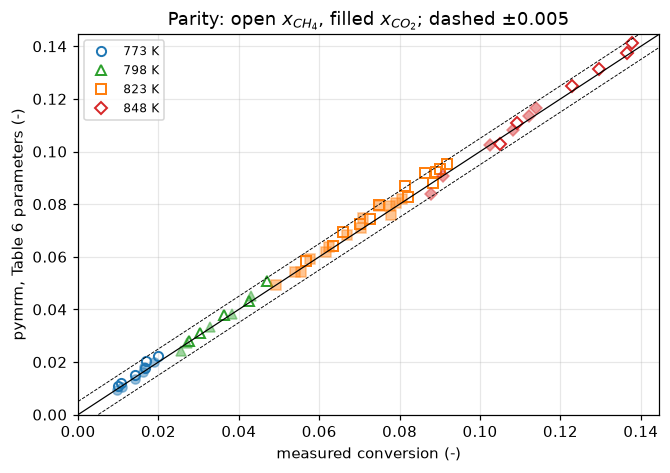

In [12]:
# 5. Against the measurements, and the defects only the measurements can see.
LONG = 0.28   # W/F above which the reactions approach equilibrium (bins below)
BINS = [(0.12, 0.20), (0.20, LONG), (LONG, 0.42)]


def data_metrics(dev):
    """Deviation metrics from model-minus-measurement values in the order of ``obs``."""
    d = obs.assign(dev=dev)
    ch4 = d[d.quantity == "x_CH4"]
    out = {"mad_conversion": d.dev.abs().mean(), "max_dev_conversion": d.dev.abs().max(),
           "bias_conversion": d.dev.mean(), "mad_x_ch4": ch4.dev.abs().mean(),
           "mad_x_co2": d[d.quantity == "x_CO2"].dev.abs().mean(),
           "mad_rel_mean_pct": d.dev.abs().mean() / d.value.mean() * 100}
    for i, (lo, hi) in enumerate(BINS):
        out[f"bias_x_ch4_bin{i + 1}"] = ch4[(ch4.W_F >= lo) & (ch4.W_F < hi)].dev.mean()
    out["bias_short_over_long"] = out["bias_x_ch4_bin1"] / out["bias_x_ch4_bin3"]
    for T in TEMPS:
        s = ch4[(ch4.temperature_K == T) & (ch4.W_F >= LONG)]
        out[f"bias_long_{T:.0f}K"] = s.dev.mean()
    return {k: float(v) for k, v in out.items()}


DM = data_metrics(res.dev.to_numpy())
print(f"5. deviation from the {N_OBS} digitised measurements")
print(f"   MAD {DM['mad_conversion']:.5f}   worst {DM['max_dev_conversion']:.5f}   "
      f"bias {DM['bias_conversion']:+.5f} in conversion")
print(f"   relative to the mean measured conversion ({obs.value.mean():.4f}): "
      f"{DM['mad_rel_mean_pct']:.1f} %")
for k, v in DM.items():
    claims.value(k, v, unit="%" if k.endswith("_pct") else "-")

DATA_CASES = [
    (f"K1 intercept b1 {b1:g} -> {b1 + 1:g} (XuFroment(eq=...))", replace(kin, eq=(a1, b1 + 1, a2, b2))),
    (f"K2 intercept b2 {b2:g} -> {b2 + 1:g} (XuFroment(eq=...))", replace(kin, eq=(a1, b1, a2, b2 + 1))),
    (f"K_CO A {kin.A['K_CO']:g} -> 8.32e-05 (kin.edited('K_CO', A=8.32e-5))", kin.edited("K_CO", A=8.32e-5)),
    (f"k1 A {kin.A['k1']:g} -> 4.255e+15 (kin.edited('k1', A=4.255e15))", kin.edited("k1", A=4.255e15)),
    (f"k3 A {kin.A['k3']:g} -> 1.002e+15 (kin.edited('k3', A=1.002e15))", kin.edited("k3", A=1.002e15)),
    (f"K_H2 A {kin.A['K_H2']:g} -> 6.21e-09 (kin.edited('K_H2', A=6.21e-9))", kin.edited("K_H2", A=6.21e-9)),
]
CASE_MODELS = {}
print(f"\n   {'injected defect (re-solves all four reactors)':64s}{'MAD':>9}{'worst':>9}{'bias':>10}"
      f"{'MAD x_CH4':>11}{'MAD x_CO2':>11}")
print(f"   {'as published':64s}{DM['mad_conversion']:9.5f}{DM['max_dev_conversion']:9.5f}"
      f"{DM['bias_conversion']:+10.5f}{DM['mad_x_ch4']:11.5f}{DM['mad_x_co2']:11.5f}")
for lab, k in DATA_CASES:
    CASE_MODELS[lab] = solve_all(k)
    b = data_metrics(deviations(CASE_MODELS[lab]))
    for name in DM:
        brk(lab, name, b[name])
    print(f"   {lab[:64]:64s}{b['mad_conversion']:9.5f}{b['max_dev_conversion']:9.5f}"
          f"{b['bias_conversion']:+10.5f}{b['mad_x_ch4']:11.5f}{b['mad_x_co2']:11.5f}")

fig, ax = plt.subplots(figsize=(6.2, 4.4))
for T in TEMPS:
    s = res[res.temperature_K == T]
    a, c = s[s.quantity == "x_CH4"], s[s.quantity == "x_CO2"]
    ax.plot(a.value, a.model, MRK[T], color=COL[T], ms=6, mfc="none", mew=1.3, label=f"{T:.0f} K")
    ax.plot(c.value, c.model, MRK[T], color=COL[T], ms=6, alpha=0.45)
lim = [0, 1.05 * res.value.max()]
ax.plot(lim, lim, "k-", lw=0.8)
ax.plot(lim, [v + 0.005 for v in lim], "k--", lw=0.6)
ax.plot(lim, [v - 0.005 for v in lim], "k--", lw=0.6)
ax.set(xlim=lim, ylim=lim, xlabel="measured conversion (-)",
       ylabel="pymrm, Table 6 parameters (-)",
       title="Parity: open $x_{CH_4}$, filled $x_{CO_2}$; dashed $\\pm$0.005")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Both equilibrium intercepts, invisible to check 2, fail every deviation claim
here. A transposed digit in an adsorption preexponential (`K_CO`, `K_H2`) is
*not* caught by the measurements; it is caught by check 1, which is why the
round trip has to be sharp enough to see it.

**The activity factors quoted in Reuse are exercised here, not validated.** The
runs they belong to (the paper's Figures 4 and 5, and fresh catalyst) are
different chemistry that this page does not model. The rate coefficients
multiplied by each factor are run against *these* data, the reference-level
runs, so the fit can only get worse.

In [13]:
ACT = {}
for f, what in ((1.225, "the paper's Figures 4 and 5"), (2.246, "fresh catalyst")):
    ACT[f] = data_metrics(deviations(solve_all(replace(kin, activity=f))))["mad_conversion"]
    print(f"   k1, k2, k3 x {f:5.3f} ({what:28s}): MAD against this page's data {ACT[f]:.5f}")
    claims.value(f"mad_activity_{f:.3f}".replace(".", "p"), ACT[f],
                 note="exercised, not validated: these data are the reference-level runs")
_k1 = replace(kin, eq=(a1, b1 + 1, a2, b2))
for f in ACT:
    brk(DATA_CASES[0][0], f"mad_activity_{f:.3f}".replace(".", "p"),
        data_metrics(deviations(solve_all(replace(_k1, activity=f))))["mad_conversion"])

   k1, k2, k3 x 1.225 (the paper's Figures 4 and 5 ): MAD against this page's data 0.00628
   k1, k2, k3 x 2.246 (fresh catalyst              ): MAD against this page's data 0.01695


## What pymrm adds

The paper draws four curves through its points and stops. Two questions it
leaves open can be answered by running the model rather than reading it.

None of this needs pymrm as such: the same two ODEs integrate with `solve_ivp`,
and check 4 does exactly that. What the pymrm form buys is reuse (see Reuse).

**Where does the residual come from?** The deviation is not uniform: the bias
in methane conversion grows with space time.

In [14]:
print("bias in x_CH4, by space time (all four temperatures)")
for i, (lo, hi) in enumerate(BINS):
    n = int(((obs.quantity == "x_CH4") & (obs.W_F >= lo) & (obs.W_F < hi)).sum())
    print(f"   W/F {lo:.2f}-{hi:.2f}:  n = {n:2d}   bias = {DM[f'bias_x_ch4_bin{i + 1}']:+.5f}")
print(f"   short over long: {DM['bias_short_over_long']:.2f}")

# How far from equilibrium is the gas? beta_i = Q_i / K_i: 1 at equilibrium, where
# the rate of reaction i vanishes.
print("\napproach to equilibrium at 848 K (beta = Q/K; 1 = equilibrated)")
RS = {T: reference_solution(kin, T, TAU_MAX, P_T, SR, HR) for T in TEMPS}


def beta_ref(k, sol, T, tau):
    """beta_I, beta_II, beta_III on the Radau dense solution ``sol`` at space time ``tau``."""
    x = sol(tau)
    return np.array(k.beta(x[0], x[1], T, P_T, SR, HR))


for tau in (0.13, 0.20, 0.28, 0.35):
    b = beta_ref(kin, RS[848.0], 848.0, tau)
    print(f"   tau = {tau:.2f}:  I {b[0]:.3f}   II {b[1]:.3f}   III {b[2]:.3f}")
b = beta_ref(kin, RS[848.0], 848.0, TAU_MAX)
print(f"   outlet {TAU_MAX:.2f}:  I {b[0]:.3f}   II {b[1]:.3f}   III {b[2]:.3f}")


def beta_long(ms, k):
    """beta_I and beta_III at every measured x_CH4 point with W/F >= LONG."""
    s = obs[(obs.quantity == "x_CH4") & (obs.W_F >= LONG)]
    return np.array([ms[r.temperature_K].beta(r.W_F) for r in s.itertuples()])


BL = beta_long(models, kin)
print(f"\nat the measured points with W/F >= {LONG}: beta_I {BL[:, 0].min():.2f} to "
      f"{BL[:, 0].max():.2f}, beta_III {BL[:, 2].min():.2f} to {BL[:, 2].max():.2f}")
claims.value("beta_I_long_min", BL[:, 0].min())
claims.value("beta_I_long_max", BL[:, 0].max())
claims.value("beta_III_long_min", BL[:, 2].min())
claims.value("beta_III_long_max", BL[:, 2].max())
_bl = beta_long(CASE_MODELS[DATA_CASES[0][0]], DATA_CASES[0][1])
for j, name in ((0, "beta_I_long"), (2, "beta_III_long")):
    brk(DATA_CASES[0][0], f"{name}_min", _bl[:, j].min())
    brk(DATA_CASES[0][0], f"{name}_max", _bl[:, j].max())

# Sensitivity: K1, K2 and K3 each multiplied by 0.95 and 1.05, at the same
# measured long-space-time points the bias is taken over, on the same grid.
def k_halfspan(k, shift=0.05):
    out = {}
    for T in TEMPS:
        s = obs[(obs.quantity == "x_CH4") & (obs.W_F >= LONG) & (obs.temperature_K == T)]
        lo, hi = (SteamReformer(replace(k, eq_factor=f), T, P_T, SR, HR, TAU_MAX, N_TAU)
                  .solve().at(s.W_F.to_numpy(), 0) for f in (1 - shift, 1 + shift))
        out[T] = float(np.mean(np.abs(hi - lo)) / 2)
    return out


HS = k_halfspan(kin)
print(f"\nsensitivity of x_CH4 to a 5 % shift in every K_i, at the measured points with "
      f"W/F >= {LONG}, against the bias there")
for T in TEMPS:
    n = int(((obs.quantity == "x_CH4") & (obs.W_F >= LONG) & (obs.temperature_K == T)).sum())
    print(f"   {T:.0f} K (n = {n:2d}):  |half-span| {HS[T]:.4f}   observed bias "
          f"{DM[f'bias_long_{T:.0f}K']:+.4f}   ratio {HS[T] / DM[f'bias_long_{T:.0f}K']:.2f}")
    claims.value(f"k_halfspan_long_{T:.0f}K", HS[T])
RATIO = {T: HS[T] / DM[f"bias_long_{T:.0f}K"] for T in TEMPS}
for T in TEMPS:
    claims.value(f"k_halfspan_bias_ratio_{T:.0f}K", RATIO[T],
                 note="half-span of a 5 % shift in every K_i over the observed bias, W/F >= LONG")
# the wording below holds only while the hot pair is comparable and the cold pair is not
HOT, COLD = (823.0, 848.0), (773.0, 798.0)
claims.bound("k_halfspan_ratio_hot_min", min(RATIO[T] for T in HOT), min=0.5, basis="chosen",
             note="'the same size' at 823 and 848 K: ratio within a factor of two of 1")
claims.bound("k_halfspan_ratio_hot_max", max(RATIO[T] for T in HOT), max=2.0, basis="chosen",
             note="'the same size' at 823 and 848 K: ratio within a factor of two of 1")
claims.bound("k_halfspan_ratio_cold_max", max(RATIO[T] for T in COLD), max=0.5, basis="chosen",
             note="at 773 and 798 K the shift is under half the bias, so the argument fails")
for lab, k in DATA_CASES[:2]:
    hb = k_halfspan(k)
    for T in TEMPS:
        brk(lab, f"k_halfspan_long_{T:.0f}K", hb[T])
    bb = data_metrics(deviations(CASE_MODELS[lab]))
    rb = {T: hb[T] / bb[f"bias_long_{T:.0f}K"] for T in TEMPS}
    for T in TEMPS:
        brk(lab, f"k_halfspan_bias_ratio_{T:.0f}K", rb[T])
    brk(lab, "k_halfspan_ratio_hot_min", min(rb[T] for T in HOT))
    brk(lab, "k_halfspan_ratio_hot_max", max(rb[T] for T in HOT))
    brk(lab, "k_halfspan_ratio_cold_max", max(rb[T] for T in COLD))
_h25 = k_halfspan(kin, 0.25)
brk("a 25 % shift in every K_i instead of 5 % (k_halfspan(k, shift=0.25))",
    "k_halfspan_ratio_hot_max", max(_h25[T] / DM[f"bias_long_{T:.0f}K"] for T in HOT))
brk("a 25 % shift in every K_i instead of 5 % (k_halfspan(k, shift=0.25))",
    "k_halfspan_ratio_cold_max", max(_h25[T] / DM[f"bias_long_{T:.0f}K"] for T in COLD))

bias in x_CH4, by space time (all four temperatures)
   W/F 0.12-0.20:  n = 11   bias = +0.00116
   W/F 0.20-0.28:  n =  8   bias = +0.00174
   W/F 0.28-0.42:  n = 11   bias = +0.00321
   short over long: 0.36

approach to equilibrium at 848 K (beta = Q/K; 1 = equilibrated)


   tau = 0.13:  I 0.514   II 0.826   III 0.424
   tau = 0.20:  I 0.709   II 0.920   III 0.653
   tau = 0.28:  I 0.851   II 0.965   III 0.821
   tau = 0.35:  I 0.920   II 0.982   III 0.903
   outlet 0.45:  I 0.968   II 0.993   III 0.961

at the measured points with W/F >= 0.28: beta_I 0.57 to 0.90, beta_III 0.45 to 0.88

sensitivity of x_CH4 to a 5 % shift in every K_i, at the measured points with W/F >= 0.28, against the bias there
   773 K (n =  2):  |half-span| 0.0005   observed bias +0.0028   ratio 0.19
   798 K (n =  1):  |half-span| 0.0014   observed bias +0.0039   ratio 0.36
   823 K (n =  6):  |half-span| 0.0025   observed bias +0.0035   ratio 0.71
   848 K (n =  2):  |half-span| 0.0035   observed bias +0.0023   ratio 1.54


In [15]:
display(Markdown(
    f"A 5 % shift in the equilibrium constants moves the long-space-time predictions by "
    f"{HS[823.0]:.4f} at 823 K and {HS[848.0]:.4f} at 848 K, against observed biases of "
    f"{DM['bias_long_823K']:+.4f} and {DM['bias_long_848K']:+.4f} there (ratios "
    f"{RATIO[823.0]:.2f} and {RATIO[848.0]:.2f}): the same size. Xu and Froment do not report "
    f"the $K_i$ they used, so at those two temperatures the residual at long space time is "
    f"inside the uncertainty of an ingredient the paper does not supply, and cannot be "
    f"charged to the kinetics. **At 773 and 798 K that argument fails.** There the gas is further from "
    f"equilibrium ($\\beta_\\mathrm{{I}}$ down to {BL[:, 0].min():.2f} at the measured points), "
    f"the same shift moves the prediction by only {HS[773.0]:.4f} and {HS[798.0]:.4f}, "
    f"{RATIO[773.0]:.2f} and {RATIO[798.0]:.2f} of the biases ({DM['bias_long_773K']:+.4f} and "
    f"{DM['bias_long_798K']:+.4f}), and the equilibrium constants do not explain the residual. "
    f"At short space time the bias is {DM['bias_short_over_long']:.2f} of its long-space-time "
    f"value."))

A 5 % shift in the equilibrium constants moves the long-space-time predictions by 0.0025 at 823 K and 0.0035 at 848 K, against observed biases of +0.0035 and +0.0023 there (ratios 0.71 and 1.54): the same size. Xu and Froment do not report the $K_i$ they used, so at those two temperatures the residual at long space time is inside the uncertainty of an ingredient the paper does not supply, and cannot be charged to the kinetics. **At 773 and 798 K that argument fails.** There the gas is further from equilibrium ($\beta_\mathrm{I}$ down to 0.57 at the measured points), the same shift moves the prediction by only 0.0005 and 0.0014, 0.19 and 0.36 of the biases (+0.0028 and +0.0039), and the equilibrium constants do not explain the residual. At short space time the bias is 0.36 of its long-space-time value.

**Where does each reaction stop being kinetically controlled?** The $\beta$
values split the reactor into regimes: the water-gas shift equilibrates first
and well before the reforming reactions do, which is the behaviour the paper
asserts from its $V(\mathrm{II})$ plot but never shows against space time.
Below, the same thing across all four temperatures; the space time at which
each reaction reaches $\beta = 0.90$ is root-found on the Radau reference
profile (dense output), so it carries no grid error.

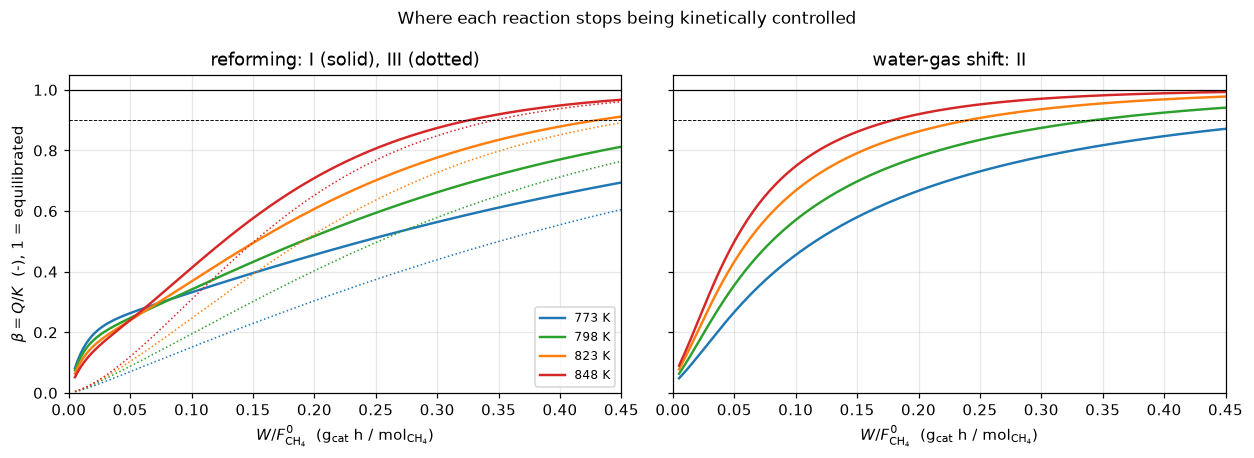

space time (g_cat h/mol_CH4) at which beta reaches 0.90, and beta at the outlet tau = 0.45; 6 of 12 crossings lie in the bed
   773 K:  I >0.45  II >0.45  III >0.45   |  beta at the outlet 0.694, 0.872, 0.605   beta_II - beta_I +0.177
   798 K:  I >0.45  II 0.343  III >0.45   |  beta at the outlet 0.813, 0.941, 0.765   beta_II - beta_I +0.129
   823 K:  I 0.430  II 0.240  III >0.45   |  beta at the outlet 0.912, 0.978, 0.892   beta_II - beta_I +0.066
   848 K:  I 0.326  II 0.179  III 0.346   |  beta at the outlet 0.968, 0.993, 0.961   beta_II - beta_I +0.025
   823 K: the shift reaches 0.90 at 0.56 of the space time reforming (I) needs
   848 K: the shift reaches 0.90 at 0.55 of the space time reforming (I) needs
largest gap between the finite-volume (1000 cells) and the Radau crossing: 4.9e-04


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
tau = np.linspace(0.005, TAU_MAX, 200)
for T in TEMPS:
    b = np.array(models[T].beta(tau)).T
    axes[0].plot(tau, b[:, 0], color=COL[T], lw=1.6, label=f"{T:.0f} K")
    axes[0].plot(tau, b[:, 2], color=COL[T], lw=1.0, ls=":")
    axes[1].plot(tau, b[:, 1], color=COL[T], lw=1.6, label=f"{T:.0f} K")
for ax, ttl in zip(axes, ["reforming: I (solid), III (dotted)", "water-gas shift: II"]):
    ax.axhline(1.0, color="k", lw=0.8)
    ax.axhline(0.90, color="k", lw=0.6, ls="--")
    ax.set(xlabel=r"$W/F^{0}_{\mathrm{CH_4}}$  (g$_\mathrm{cat}$ h / mol$_{\mathrm{CH_4}}$)",
           xlim=(0, TAU_MAX), ylim=(0, 1.05), title=ttl)
axes[0].set_ylabel(r"$\beta = Q/K$  (-), 1 = equilibrated")
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Where each reaction stops being kinetically controlled", fontsize=11)
fig.tight_layout()
plt.show()


def tau90(k, sol, T, i):
    """Space time at which beta_i reaches 0.90 on the Radau dense solution ``sol``;
    None if the bed ends first."""
    f = lambda t: beta_ref(k, sol, T, t)[i] - 0.90   # noqa: E731
    return brentq(f, models[T].tau_c[0], TAU_MAX, xtol=1e-12) if f(TAU_MAX) > 0 else None


def tau90_fv(m, i):
    """The same crossing root-found on the finite-volume profile of model ``m``."""
    f = lambda t: m.beta(t)[i] - 0.90   # noqa: E731
    return brentq(f, m.tau_c[0], TAU_MAX, xtol=1e-12) if f(TAU_MAX) > 0 else None


def beta_outlet(k, sol, T):
    return beta_ref(k, sol, T, TAU_MAX)


BO = {T: beta_outlet(kin, RS[T], T) for T in TEMPS}
N90 = claims.count("tau90_crossings_in_bed", [BO[T][i] for T in TEMPS for i in range(3)],
                   0.90, min_margin=0.005,
                   note="(T, reaction) pairs with beta > 0.90 at the outlet")
TAU90 = {(T, i): tau90(kin, RS[T], T, i) for T in TEMPS for i in range(3)}
print(f"space time (g_cat h/mol_CH4) at which beta reaches 0.90, and beta at the outlet "
      f"tau = {TAU_MAX}; {N90} of 12 crossings lie in the bed")
for T in TEMPS:
    hit = [f"{TAU90[T, i]:.3f}" if TAU90[T, i] is not None else ">0.45" for i in range(3)]
    print(f"   {T:.0f} K:  I {hit[0]:6s} II {hit[1]:6s} III {hit[2]:6s}  |  beta at the outlet "
          f"{BO[T][0]:.3f}, {BO[T][1]:.3f}, {BO[T][2]:.3f}   beta_II - beta_I {BO[T][1] - BO[T][0]:+.3f}")
for T in (823.0, 848.0):
    print(f"   {T:.0f} K: the shift reaches 0.90 at {TAU90[T, 1] / TAU90[T, 0]:.2f} of the space "
          "time reforming (I) needs")
GAP = [BO[T][1] - BO[T][0] for T in TEMPS]
claims.value("beta_gap_outlet_min", min(GAP))
claims.value("beta_gap_outlet_max", max(GAP))
for T in (823.0, 848.0):
    claims.value(f"tau90_ratio_II_I_{T:.0f}K", TAU90[T, 1] / TAU90[T, 0], rtol=1e-3)
for (T, i) in ((798.0, 1), (823.0, 0), (823.0, 1), (848.0, 0), (848.0, 1), (848.0, 2)):
    claims.value(f"tau90_{('I', 'II', 'III')[i]}_{T:.0f}K", TAU90[T, i], rtol=1e-3)

# The crossings above are root-found on the Radau profile; the finite-volume
# profile runs late by its first-order grid error. The largest gap, over the
# crossings that lie in the bed, is bounded by the grid error measured above.
CROSS = [(T, i) for (T, i) in TAU90 if TAU90[T, i] is not None]
FV_GAP = max(abs(tau90_fv(models[T], i) - TAU90[T, i]) for T, i in CROSS)
print(f"largest gap between the finite-volume ({N_TAU} cells) and the Radau crossing: {FV_GAP:.1e}")
claims.bound("beta90_fv_vs_radau_max", FV_GAP, max=1e-3, basis="theory",
             note="max over the in-bed crossings of |finite volumes - Radau|, first-order grid error")
_coarse = solve_all(kin, 100)
brk("a tenth of the cells (n_tau = 100), crossings root-found on the finite-volume profile",
    "beta90_fv_vs_radau_max",
    max(abs(tau90_fv(_coarse[T], i) - TAU90[T, i]) for T, i in CROSS))

_lab, _k = DATA_CASES[1]                 # the K2 intercept: the shift's equilibrium moves
_rs = {T: reference_solution(_k, T, TAU_MAX, P_T, SR, HR) for T in TEMPS}
_bo = {T: beta_outlet(_k, _rs[T], T) for T in TEMPS}
_gap = [_bo[T][1] - _bo[T][0] for T in TEMPS]
brk(_lab, "beta_gap_outlet_min", min(_gap))
brk(_lab, "beta_gap_outlet_max", max(_gap))
brk(_lab, "tau90_crossings_in_bed", int(sum(_bo[T][i] > 0.90 for T in TEMPS for i in range(3))))
for T in (823.0, 848.0):
    t2, t1 = tau90(_k, _rs[T], T, 1), tau90(_k, _rs[T], T, 0)
    brk(_lab, f"tau90_ratio_II_I_{T:.0f}K", np.nan if t2 is None or t1 is None else t2 / t1)
for (T, i) in ((798.0, 1), (823.0, 0), (823.0, 1), (848.0, 0), (848.0, 1), (848.0, 2)):
    t = tau90(_k, _rs[T], T, i)
    brk(_lab, f"tau90_{('I', 'II', 'III')[i]}_{T:.0f}K", np.nan if t is None else t)

### The break table

Every number above is registered as a claim; each row injects one defect
through an argument or a parameter and reports what the claim becomes, and
whether the claim's own check catches it. A row that does not catch is kept
when it shows a check's blind spot (the intercepts in check 2, the adsorption
preexponentials in check 5, the fourth-figure slip in check 1).

In [17]:
print(f"{'injected defect':<70} {'claim':<42} {'clean':>11} {'broken':>11}  caught")
for row, metric, clean, broken, caught in BREAK:
    if claims.metrics[metric]["kind"] == "bound":
        shown, br = f"(here {clean:.2g})", f"{float(broken):.3g}"
    else:
        shown, br = f"{float(clean):11.5g}", f"{float(broken):11.5g}"
    print(f"{row[:70]:<70} {metric[:42]:<42} {shown:>11} {br:>11}  {'yes' if caught else 'NO'}")
_caught = {mt for _, mt, _, _, c in BREAK if c}
_open = sorted(k for k in claims.metrics if k not in _caught and not claims.metrics[k].get("structural"))
_struct = sorted(k for k in claims.metrics if claims.metrics[k].get("structural"))
print(f"\n{len(BREAK)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at least "
      f"one row; structural: {', '.join(_struct) or 'none'}; open: {', '.join(_open) or 'none'}")

injected defect                                                        claim                                            clean      broken  caught
the bed outlet TAU_MAX read as the last measurement                    W_F_measured_max                                0.4046        0.45  yes
regular expression matching the W/F error instead of the conversion er digitisation_error_conversion                   0.0006      0.0007  yes
K_CO A 8.23e-5 -> 8.32e-5 (rows_with('K_CO', 'A', '8.32e-5'))          param_round_trip_worst_pct                      1.4432      1.4432  NO
K_CO A 8.23e-5 -> 8.32e-5 (rows_with('K_CO', 'A', '8.32e-5'))          param_round_trip_worst_ratio_to_precision       2.3203      4.8973  yes
K_CO A 8.23e-5 -> 8.32e-5 (rows_with('K_CO', 'A', '8.32e-5'))          param_round_trip_ratio_sum                      10.438       13.67  yes
k3 A 1.020e15 -> 1.002e15 (rows_with('k3', 'A', '1.002e15'))           param_round_trip_worst_pct                      1.4432      1.2844  y

## Reuse

**The kinetics on their own.** `XuFroment.rates(x_CH4, x_CO2, T, p_t, sr, hr)`
returns $r_1, r_2, r_3$ in kmol/(kg$_\mathrm{cat}$ h) and has no dependence on
the reactor model. `partial_pressures` is the only piece tied to the
single-feed parameterisation; swap it for a general mole-fraction vector and
the rate equations carry over unchanged.

**Three activity levels, and only one of them is tested here.** Multiply
$k_1, k_2, k_3$ (`XuFroment(activity=...)`) by

- **1** for the steam-reforming reference level: what this page uses, what
  Tables 5 and 6 are, and the only level the measurements on this page
  belong to;
- **1.225** to reproduce the paper's Figures 4 and 5 (reverse water-gas shift
  and methanation);
- **2.246** for fresh catalyst.

The last two are **transcriptions from the paper's text that nothing on this
page validates.** Check 5 executes them, so they are at least run, and shows
what they do to the fit against *these* data, which is to make it worse, as it
must. Reproducing Figures 4 and 5 would need the reverse water-gas shift and
methanation feeds, which this page does not model. Treat both factors as
unchecked.

**The round trip is the check on the parameter reading, and it has a floor.**
Check 1 measures it: a slip smaller than a row's own printed precision is
invisible, and the worst per-row deviation cannot see anything smaller than the
baseline scatter that the 0.1 kJ/mol precision of $E$ already produces. If you
re-read these tables from your own render, compare
`param_round_trip_ratio_sum`, not the worst percentage.

**The equilibrium constants are the weak ingredient.** They are not from this
paper, check 2 cannot see their intercepts, and at the two hotter temperatures
the long-space-time residual is the size of a 5 % change in them. A model that
replaces them by a thermodynamic database should re-run check 5.

**Going further with the same residual.** `SteamReformer.residual` is the whole
model. To make the tube non-isothermal, add an enthalpy field to the state (a
third entry on the last axis) and a wall-flux term; to resolve the pellet, keep
this as the bulk equation and couple a `B1.1`-style intraparticle model to it,
which is `D1.4`. First-order upwind is enough here because the error is checked
at the points used (check 4); a profile with a sharp front would want
`ConvFluxTVD`.

**Related pages.** `B1.1` (intraparticle diffusion and reaction, the resistance
these intrinsic kinetics deliberately exclude), `D1.4` (fixed bed with resolved
particles), `C2.2`, `C2.6`, `D3.1`.

**Cite the source, not this page**, for the kinetics: Xu, J. and Froment, G. F.,
*Methane steam reforming, methanation and water-gas shift: I. Intrinsic
kinetics*, AIChE Journal **35**(1) 88-96 (1989),
[doi:10.1002/aic.690350109](https://doi.org/10.1002/aic.690350109).

In [18]:
# Prose numbers: each literal as written in the Markdown above, checked against its claim.
claims.says("0.93", "e_precision_share_pct")           # Validation intro, Reuse
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for C2.1:
  W_F_measured_max                          = 0.4046           value  rtol 0.05
  digitisation_error_conversion             = 0.0006           value  rtol 0.05
  param_round_trip_worst_pct                = 1.4432           value  rtol 0.05
  param_round_trip_worst_ratio_to_precision = 2.3203           value  rtol 0.05
  param_round_trip_ratio_sum                = 10.438           value  rtol 0.05
  e_precision_share_pct                     = 0.92808          value  rtol 0.05
  tref_slip_factor_K_CH4                    = 0.22103          value  rtol 0.05
  tref_slip_factor_K_H2O                    = 33.033           value  rtol 0.05
  equilibrium_vs_table7_worst_pct           = 1.926            value  rtol 0.05
  atom_balance_worst                        = (here 2.2e-16)   bound  bound <= 1e-12 [identity]
  min_partial_pressure_rel                  = (here 2.5e-06)   bound  bound >= 0 [theory]
  disc_error_max_n1000                      = 4.1404e-05       value  rtol 0.